# 06 — Telling Chronos-2 what helped XGBoost

Every gain of the XGBoost baseline came from giving it information: calendar, prices, events, statistics of
the past. Chronos-2 can take extra inputs too, so the obvious next step is to hand it the same knowledge.
Three families of attempts, each compared with the out-of-the-box model of notebook 05 (*vanilla*):

1. **known covariates** from the XGBoost feature set (calendar, price, SNAP days, events);
2. **cross-learning**: letting the series of a batch attend to each other;
3. **blank periods** (notebook 02), encoded three ways: as an input, as a second target, as masked values.

The question is not obvious either way. A feature-based model needs metadata because it cannot see the
history; Chronos-2 *reads* the history, so anything derived from the timestamp or from the target's own
past should be redundant. But prices, SNAP days and events are genuinely exogenous: the model cannot infer
them from the sales alone.

**Protocol.** Validation window only (no decision is ever taken on the test window). Same context length
as vanilla (the whole history), cross-learning off unless stated. Every run is saved to
`artifacts/experiments/` under a name describing it, and read back on later runs.

**One diagnostic beyond the metrics.** For every run we also measure the width of the forecast distribution
(mean distance between quantiles 0.2 and 0.8). An input the model cannot turn into a rule tends to make it
*less sure* before it makes it worse on average: a widening is the signature of an uninformative input.

In [1]:
%load_ext autoreload
%autoreload 2

from datetime import timedelta

import polars as pl
import matplotlib.pyplot as plt

from m5_chronos2.data import ARTIFACTS_DIR, HORIZON, roster_name
from m5_chronos2.evaluation import actuals, make_windows
from m5_chronos2.metrics import METRICS, compare, join_truth
from m5_chronos2.blank_periods import add_silent_runs
from m5_chronos2.chronos2 import (
    ALL_KNOWN_COVARIATES,
    KNOWN_COVARIATE_BLOCKS,
    MIN_BLANK_DAYS,
    cached,
    experiment_path,
    forecast,
    future_window,
    history,
    known_covariate_table,
    past_blank_flags,
)
from m5_chronos2.gbdt_features import calendar_by_day, event_uplift, group_daily_means, load_all_series_long
from m5_chronos2.plots import MAIN_COLOR, MUTED_TEXT_COLOR, TEXT_COLOR, plot_change_bars, use_blog_style

use_blog_style()

## Settings

In [2]:
SAMPLE_SIZE = 500
SEED = 42
NAME = roster_name(SAMPLE_SIZE, SEED)
from m5_chronos2.chronos2 import resolve_device
DEVICE = resolve_device()   # cpu on the laptop, cuda on the tower

CONTEXT_LENGTH = None        # model maximum = the whole history, as in notebook 05
CROSS_LEARNING_BATCH = 100   # series per group when cross-learning is on (the vendor's tuning)
SHUFFLE_SEED = 0             # order of the series for cross-learning (see section 2)

In [3]:
sales = pl.read_parquet(ARTIFACTS_DIR / f"sales_flags_{NAME}.parquet")
truth = actuals(sales)
windows = make_windows()
VALIDATION_ORIGIN = windows.filter(pl.col("role") == "validation")["origin"][0]
validation_roster = pl.read_parquet(ARTIFACTS_DIR / f"eval_roster_{NAME}.parquet").filter(pl.col("role") == "validation")
series_ids = sales["id"].unique().sort().to_list()

context = history(sales, VALIDATION_ORIGIN)
vanilla = pl.read_parquet(ARTIFACTS_DIR / "predictions" / f"chronos2_vanilla_{NAME}.parquet").filter(
    pl.col("origin") == VALIDATION_ORIGIN
)

Helpers: every run goes into `runs`; `summary` scores a list of runs against vanilla, with the change of
each metric in % (negative = better than vanilla) and the change of the distribution width.

In [4]:
runs = {"vanilla": vanilla}

def run(name, compute):
    runs[name] = cached(experiment_path(name, NAME), compute)
    # An input that never reaches the model leaves the forecast unchanged: catch it now.
    change = (
        runs[name].join(vanilla, on=["id", "date"], suffix="_vanilla")
        .select((pl.col("y_pred") - pl.col("y_pred_vanilla")).abs().max() + (pl.col("q0.9") - pl.col("q0.9_vanilla")).abs().max())
        .item()
    )
    if change == 0:
        print(f"  WARNING: {name} is identical to vanilla: the extra input did not reach the model")
    return runs[name]


def summary(names, by=None):
    scored = {name: join_truth(runs[name], truth, validation_roster) for name in names}
    table = compare(scored, by=by, reference="vanilla")
    keys = [] if by is None else [by]

    widths = pl.concat([
        scored_table.with_columns((pl.col("q0.8") - pl.col("q0.2")).alias("width"), pl.lit(name).alias("model"))
        .group_by(["model"] + keys).agg(pl.col("width").mean())
        for name, scored_table in scored.items()
    ])
    reference = widths.filter(pl.col("model") == "vanilla").select(keys + [pl.col("width").alias("vanilla_width")])
    widths = widths.join(reference, on=keys) if keys else widths.join(reference, how="cross")
    widths = widths.select(["model"] + keys + [(100 * (pl.col("width") / pl.col("vanilla_width") - 1)).alias("width_change_%")])

    table = table.join(widths, on=["model"] + keys, how="left")
    columns = ["model"] + keys + ["n_series"] + [f"{m}_change_%" for m in METRICS] + ["width_change_%"]
    return table.select(columns)

## 1. Known covariates from the XGBoost feature set

How each feature of notebook 04 translates into a Chronos-2 input:

| XGBoost feature | Chronos-2 input | tested |
|---|---|---|
| day of week, month | known covariate (`calendar`) | yes |
| price, 7- and 14-day price momentum | known covariate (`price`): prices are set in advance and given for the window | yes |
| SNAP day, event uplift | known covariate (`snap_events`): published calendar | yes |
| department, store | no input for static attributes; a constant covariate carries no time information | no |
| lags, rolling means, running mean and variance of the series | nothing to pass: they summarise the history the model already reads | no |
| days since first sale | equals the history length the model sees | no |
| department × store and item aggregates | past-only covariates (other series' sales): out of scope here | no |

The event uplift is computed exactly as in notebook 04, from the item-level means of **all** 30,490 series
up to the origin (this loads the full sales file once, about 1 GB, then the result is cached).

In [5]:
calendar = calendar_by_day()
VALIDATION_DAY = calendar.filter(pl.col("date") == VALIDATION_ORIGIN)["day"][0]

def compute_uplift():
    all_long = load_all_series_long()
    item_means = group_daily_means(all_long, ["item_id"], VALIDATION_DAY)
    return event_uplift(item_means, VALIDATION_DAY)

uplift = cached(ARTIFACTS_DIR / "experiments" / f"event_uplift_origin{VALIDATION_ORIGIN}.parquet", compute_uplift)
covariates = known_covariate_table(sales, uplift)

context_known = context.join(covariates, on=["id", "date"], how="left")
future_known = future_window(covariates, VALIDATION_ORIGIN, series_ids)
assert future_known.height == len(series_ids) * HORIZON
assert future_known.select(ALL_KNOWN_COVARIATES).null_count().sum_horizontal()[0] == 0, "a known covariate is missing in the window"
future_known.head()

id,date,day_of_week,month,sell_price,sell_price_lag_7,sell_price_lag_14,snap,event_uplift
str,date,f64,f64,f64,f64,f64,f64,f64
"""FOODS_1_001_WI_3_evaluation""",2016-03-28,0.0,3.0,2.24,0.0,0.0,0.0,0.018635
"""FOODS_1_001_WI_3_evaluation""",2016-03-29,1.0,3.0,2.24,0.0,4.4409e-16,0.0,0.069342
"""FOODS_1_001_WI_3_evaluation""",2016-03-30,2.0,3.0,2.24,0.0,0.0,0.0,0.076956
"""FOODS_1_001_WI_3_evaluation""",2016-03-31,3.0,3.0,2.24,0.0,4.4409e-16,0.0,-0.001557
"""FOODS_1_001_WI_3_evaluation""",2016-04-01,4.0,4.0,2.24,0.0,0.0,0.0,-0.034793


One run per block, then all blocks together.

In [6]:
known_blocks = {**KNOWN_COVARIATE_BLOCKS, "all_known": ALL_KNOWN_COVARIATES}

for block, names in known_blocks.items():
    print(f"{block}: {names}")
    run(f"known_{block}", lambda names=names: forecast(
        context_known, VALIDATION_ORIGIN, known_covariates=names, future=future_known,
        context_length=CONTEXT_LENGTH, device=DEVICE,
    ))

known_runs = ["vanilla"] + [f"known_{block}" for block in known_blocks]
summary(known_runs)

calendar: ['day_of_week', 'month']
price: ['sell_price', 'sell_price_lag_7', 'sell_price_lag_14']
snap_events: ['snap', 'event_uplift']
all_known: ['day_of_week', 'month', 'sell_price', 'sell_price_lag_7', 'sell_price_lag_14', 'snap', 'event_uplift']


model,n_series,MAE_change_%,WMAPE_change_%,P90_change_%,WQL_change_%,RQL_change_%,width_change_%
str,u32,f64,f64,f64,f64,f64,f32
"""vanilla""",473,-1.1102e-14,0.0,0.0,0.0,0.0,0.0
"""known_calendar""",473,0.364511,0.364511,1.374763,0.220327,1.873329,-0.341827
"""known_price""",473,0.455133,0.455133,0.85648,0.201992,-0.440306,-1.131165
"""known_snap_events""",473,0.156518,0.156518,1.070827,0.451685,0.940326,-2.418894
"""known_all_known""",473,-0.551397,-0.551397,-0.748552,-0.268642,-0.649223,-1.512814


Same comparison per horizon bucket.

In [7]:
summary(known_runs, by="horizon_bucket").sort("model", "horizon_bucket")

model,horizon_bucket,n_series,MAE_change_%,WMAPE_change_%,P90_change_%,WQL_change_%,RQL_change_%,width_change_%
str,str,u32,f64,f64,f64,f64,f64,f32
"""known_all_known""","""days 01-07""",473,-0.549681,-0.549681,-1.538636,-0.71985,-2.623309,-0.237012
"""known_all_known""","""days 08-14""",473,-0.691988,-0.691988,-4.353238,-0.225205,-1.273717,-2.107352
"""known_all_known""","""days 15-21""",473,-0.584719,-0.584719,-0.960845,-0.256421,0.790315,-1.516944
"""known_all_known""","""days 22-28""",473,-0.38651,-0.38651,3.395155,0.099592,0.413567,-2.153867
"""known_calendar""","""days 01-07""",473,-0.501184,-0.501184,1.464693,-0.787285,-0.488825,1.662457
…,…,…,…,…,…,…,…,…
"""known_snap_events""","""days 22-28""",473,0.048179,0.048179,5.479293,0.716167,1.468225,-3.264356
"""vanilla""","""days 01-07""",473,0.0,0.0,0.0,0.0,0.0,0.0
"""vanilla""","""days 08-14""",473,0.0,0.0,0.0,0.0,0.0,0.0


### Does the distribution widen?

Pooled over the scored series: the mean 20%–80% band of each day ahead, vanilla (gray) against the run with
all known covariates (blue).

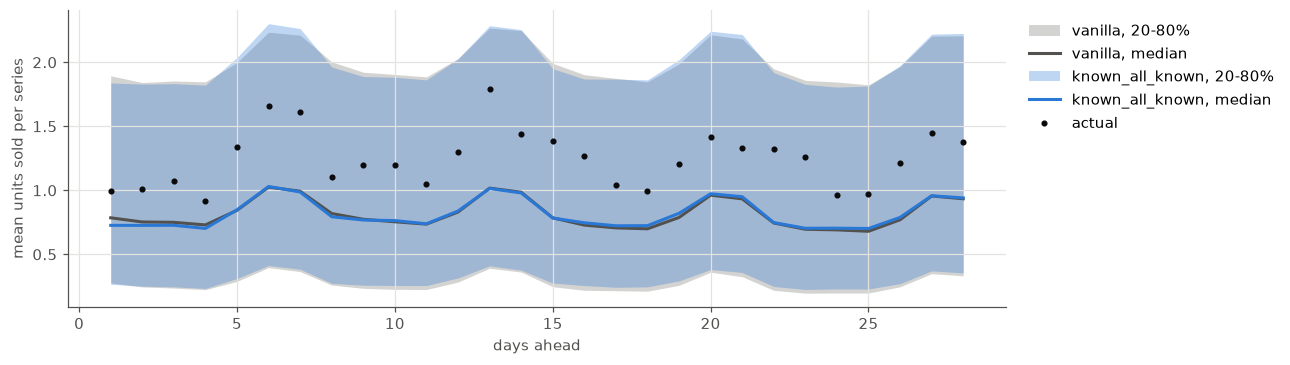

In [8]:
def pooled_band(predictions):
    scored = join_truth(predictions, truth, validation_roster)
    return (
        scored.group_by("horizon")
        .agg(pl.col("q0.2").mean(), pl.col("q0.8").mean(), pl.col("y_pred").mean(), pl.col("y").mean())
        .sort("horizon")
    )

def plot_bands(ax, reference_name, tested_name):
    for name, color, alpha in [(reference_name, MUTED_TEXT_COLOR, 0.25), (tested_name, MAIN_COLOR, 0.30)]:
        band = pooled_band(runs[name])
        ax.fill_between(band["horizon"].to_numpy(), band["q0.2"].to_numpy(), band["q0.8"].to_numpy(),
                        color=color, alpha=alpha, linewidth=0, label=f"{name}, 20-80%")
        ax.plot(band["horizon"].to_numpy(), band["y_pred"].to_numpy(), color=color, label=f"{name}, median")
    ax.plot(band["horizon"].to_numpy(), band["y"].to_numpy(), color=TEXT_COLOR, linestyle="none",
            marker="o", markersize=3, label="actual")
    ax.set_xlabel("days ahead")
    ax.set_ylabel("mean units sold per series")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))

fig, ax = plt.subplots(figsize=(11, 3.5))
plot_bands(ax, "vanilla", "known_all_known")
plt.show()

## 2. Cross-learning

With `cross_learning=True`, the series of a batch share one attention group: each series' forecast can use
the others'. Two consequences:
- the result depends on **which** series share a batch. Our series are sorted by id, i.e. by category and
  department, so consecutive batches would be almost single-department groups. To test cross-learning
  itself, not a grouping, the series are put in a random (seeded) order first;
- a batch of 100 series means 5 groups for our 500 series.

In [9]:
shuffled_ids = pl.Series(series_ids).shuffle(seed=SHUFFLE_SEED).to_list()   # sorted first, so the seed pins the order
order = pl.DataFrame({"id": shuffled_ids}).with_row_index("position")
context_shuffled = context.join(order, on="id").sort("position", "date").drop("position")

groups = (
    order.with_columns((pl.col("position") // CROSS_LEARNING_BATCH).alias("group"))
    .join(sales.select("id", "cat_id").unique(), on="id")
    .group_by("group", "cat_id").len()
    .pivot(on="cat_id", index="group", values="len").sort("group")
)
print("Series per category in each attention group:")
groups

Series per category in each attention group:


group,HOBBIES,HOUSEHOLD,FOODS
u32,u32,u32,u32
0,13,42,45
1,24,31,45
2,21,39,40
3,19,31,50
4,25,34,41


In [10]:
run("cross_learning", lambda: forecast(
    context_shuffled, VALIDATION_ORIGIN, context_length=CONTEXT_LENGTH,
    cross_learning=True, batch_size=CROSS_LEARNING_BATCH, device=DEVICE,
))
summary(["vanilla", "cross_learning"])

model,n_series,MAE_change_%,WMAPE_change_%,P90_change_%,WQL_change_%,RQL_change_%,width_change_%
str,u32,f64,f64,f64,f64,f64,f32
"""vanilla""",473,-1.1102e-14,0.0,0.0,0.0,0.0,0.0
"""cross_learning""",473,0.851014,0.851014,0.987333,1.122939,-5.605762,-3.662497


In [11]:
summary(["vanilla", "cross_learning"], by="horizon_bucket").sort("model", "horizon_bucket")

model,horizon_bucket,n_series,MAE_change_%,WMAPE_change_%,P90_change_%,WQL_change_%,RQL_change_%,width_change_%
str,str,u32,f64,f64,f64,f64,f64,f32
"""cross_learning""","""days 01-07""",473,0.76292,0.76292,0.046687,1.011846,-6.498575,-3.717113
"""cross_learning""","""days 08-14""",473,1.622747,1.622747,0.172702,1.592258,-5.904427,-3.854167
"""cross_learning""","""days 15-21""",473,0.644787,0.644787,0.694309,0.982824,-5.470037,-3.599757
"""cross_learning""","""days 22-28""",473,0.394557,0.394557,2.966239,0.90625,-4.617994,-3.477842
"""vanilla""","""days 01-07""",473,0.0,0.0,0.0,0.0,0.0,0.0
"""vanilla""","""days 08-14""",473,0.0,0.0,0.0,0.0,0.0,0.0
"""vanilla""","""days 15-21""",473,0.0,0.0,0.0,0.0,0.0,0.0
"""vanilla""","""days 22-28""",473,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Blank periods

Notebook 02 established that blank periods (14+ consecutive days without a sale while on sale) are **real
zeros**: the item was on the shelf and nobody bought it. They are part of the truth we forecast, and
nothing tells when they start. Chronos-2 offers three ways to point them out, which XGBoost could not use at
all (the flag is not known in the future):

- **(a) past-only covariate**: a 0/1 `is_blank` column next to the sales, known up to the origin only;
- **(b) second target**: forecast `sales` and `is_blank` jointly (multivariate), hoping the model learns
  that a predicted blank period means near-zero sales;
- **(c) masked values**: replace sales inside blank periods by NaN, which Chronos-2 treats as unobserved,
  so that the model does not lower its expectations because of them.

**A leak to avoid first.** The flags saved by notebook 02 were computed on the whole data: a silent run that
starts before the origin and goes on after it is measured with days the model must not see. They are
recomputed on the history alone.

In [12]:
context_blank = past_blank_flags(context).with_columns(pl.col("is_blank").cast(pl.Float64))

changed = (
    context.select("id", "date", "is_blank")
    .join(context_blank.select("id", "date", pl.col("is_blank").alias("is_blank_past_only")), on=["id", "date"])
    .filter(pl.col("is_blank") != (pl.col("is_blank_past_only") == 1))
)
print(f"History days inside a blank period: {context_blank['is_blank'].mean():.1%}")
print(f"History days whose flag changes once the future is hidden: {changed.height}")

History days inside a blank period: 27.1%
History days whose flag changes once the future is hidden: 307


In [13]:
# (a) past-only covariate
run("blank_past_covariate", lambda: forecast(
    context_blank, VALIDATION_ORIGIN, past_covariates=["is_blank"], context_length=CONTEXT_LENGTH, device=DEVICE,
))

# (b) second target: both channels are saved, the sales channel is scored
multivariate = cached(experiment_path("blank_second_target_both_channels", NAME), lambda: forecast(
    context_blank, VALIDATION_ORIGIN, target=["sales", "is_blank"], context_length=CONTEXT_LENGTH, device=DEVICE,
))
runs["blank_second_target"] = multivariate.filter(pl.col("target_name") == "sales").drop("target_name")

# (c) blank days masked as unobserved
context_masked = context_blank.with_columns(
    pl.when(pl.col("is_blank") == 1).then(None).otherwise(pl.col("sales")).alias("sales")
)
run("blank_nan_mask", lambda: forecast(context_masked, VALIDATION_ORIGIN, context_length=CONTEXT_LENGTH, device=DEVICE))

blank_runs = ["vanilla", "blank_past_covariate", "blank_second_target", "blank_nan_mask"]
summary(blank_runs)

model,n_series,MAE_change_%,WMAPE_change_%,P90_change_%,WQL_change_%,RQL_change_%,width_change_%
str,u32,f64,f64,f64,f64,f64,f32
"""vanilla""",473,-1.1102e-14,0.0,0.0,0.0,0.0,0.0
"""blank_past_covariate""",473,-0.079072,-0.079072,0.35964,0.099001,-3.593124,-2.672994
"""blank_second_target""",473,-0.079072,-0.079072,0.35964,0.099001,-3.593124,-2.672994
"""blank_nan_mask""",473,2.323921,2.323921,0.053463,1.98509,9.728935,11.261535


In [14]:
summary(blank_runs, by="horizon_bucket").sort("model", "horizon_bucket")

model,horizon_bucket,n_series,MAE_change_%,WMAPE_change_%,P90_change_%,WQL_change_%,RQL_change_%,width_change_%
str,str,u32,f64,f64,f64,f64,f64,f32
"""blank_nan_mask""","""days 01-07""",473,1.967305,1.967305,0.772003,1.953393,7.202639,11.821711
"""blank_nan_mask""","""days 08-14""",473,2.377034,2.377034,0.109657,1.852192,10.35249,11.038256
"""blank_nan_mask""","""days 15-21""",473,2.021699,2.021699,-1.10902,1.882436,9.712033,10.951889
"""blank_nan_mask""","""days 22-28""",473,2.89558,2.89558,2.37172,2.243656,11.548055,11.250806
"""blank_past_covariate""","""days 01-07""",473,-0.639553,-0.639553,-0.806471,-0.695287,-3.433074,-2.181566
…,…,…,…,…,…,…,…,…
"""blank_second_target""","""days 22-28""",473,-0.613108,-0.613108,1.744479,-0.169424,-4.997092,-3.141278
"""vanilla""","""days 01-07""",473,0.0,0.0,0.0,0.0,0.0,0.0
"""vanilla""","""days 08-14""",473,0.0,0.0,0.0,0.0,0.0,0.0


### 3b. Is the blank channel predictable at all?

Before building anything on a forecast of blank periods (such as a two-stage model: first "blank or not",
then sales), check that blank periods can be forecast. Three sources of flags over the validation window,
for the scored series:
- **actual**: the real blank days (whole-data flags: this is the truth);
- **second target**: the model's forecast of `is_blank`, flagged when its median is at least 0.5;
- **vanilla**: blank periods read off the vanilla sales forecast, with the definition of notebook 02 —
  history followed by the forecast (a day counts as a sale when the median is at least 0.5 unit), and runs
  of at least 14 silent days.

In [15]:
window = (pl.col("date") > VALIDATION_ORIGIN) & (pl.col("date") <= VALIDATION_ORIGIN + timedelta(days=HORIZON))
scored_ids = validation_roster["id"].to_list()

actual_flags = sales.filter(window, pl.col("id").is_in(scored_ids)).select("id", "date", pl.col("is_blank").alias("actual"))

second_target_flags = multivariate.filter(pl.col("target_name") == "is_blank").select(
    "id", "date", (pl.col("y_pred") >= 0.5).alias("second_target")
)

forecast_as_sales = vanilla.select("id", "date", (pl.col("y_pred") >= 0.5).cast(pl.Int64).alias("sales"))
history_and_forecast = pl.concat([context.select("id", "date", "sales"), forecast_as_sales]).with_columns(
    pl.lit(True).alias("is_on_sale")
)
vanilla_flags = (
    add_silent_runs(history_and_forecast)
    .filter(window)
    .select("id", "date", (pl.col("silent_run_length") >= MIN_BLANK_DAYS).alias("vanilla"))
)

flags = actual_flags.join(second_target_flags, on=["id", "date"]).join(vanilla_flags, on=["id", "date"])

def agreement(source):
    hits = (flags[source] & flags["actual"]).sum()
    return {
        "source": source,
        "flagged days": int(flags[source].sum()),
        "precision": hits / max(flags[source].sum(), 1),
        "recall": hits / max(flags["actual"].sum(), 1),
    }

print(f"Actual blank days in the window: {flags['actual'].sum()} of {flags.height}")
pl.DataFrame([agreement("second_target"), agreement("vanilla")])

Actual blank days in the window: 2000 of 13244


source,flagged days,precision,recall
str,i64,f64,f64
"""second_target""",1483,0.548213,0.4065
"""vanilla""",8696,0.220676,0.9595


Every scored series that at least one source flags, one row each; one panel per source.

319 of 473 scored series are flagged by at least one source


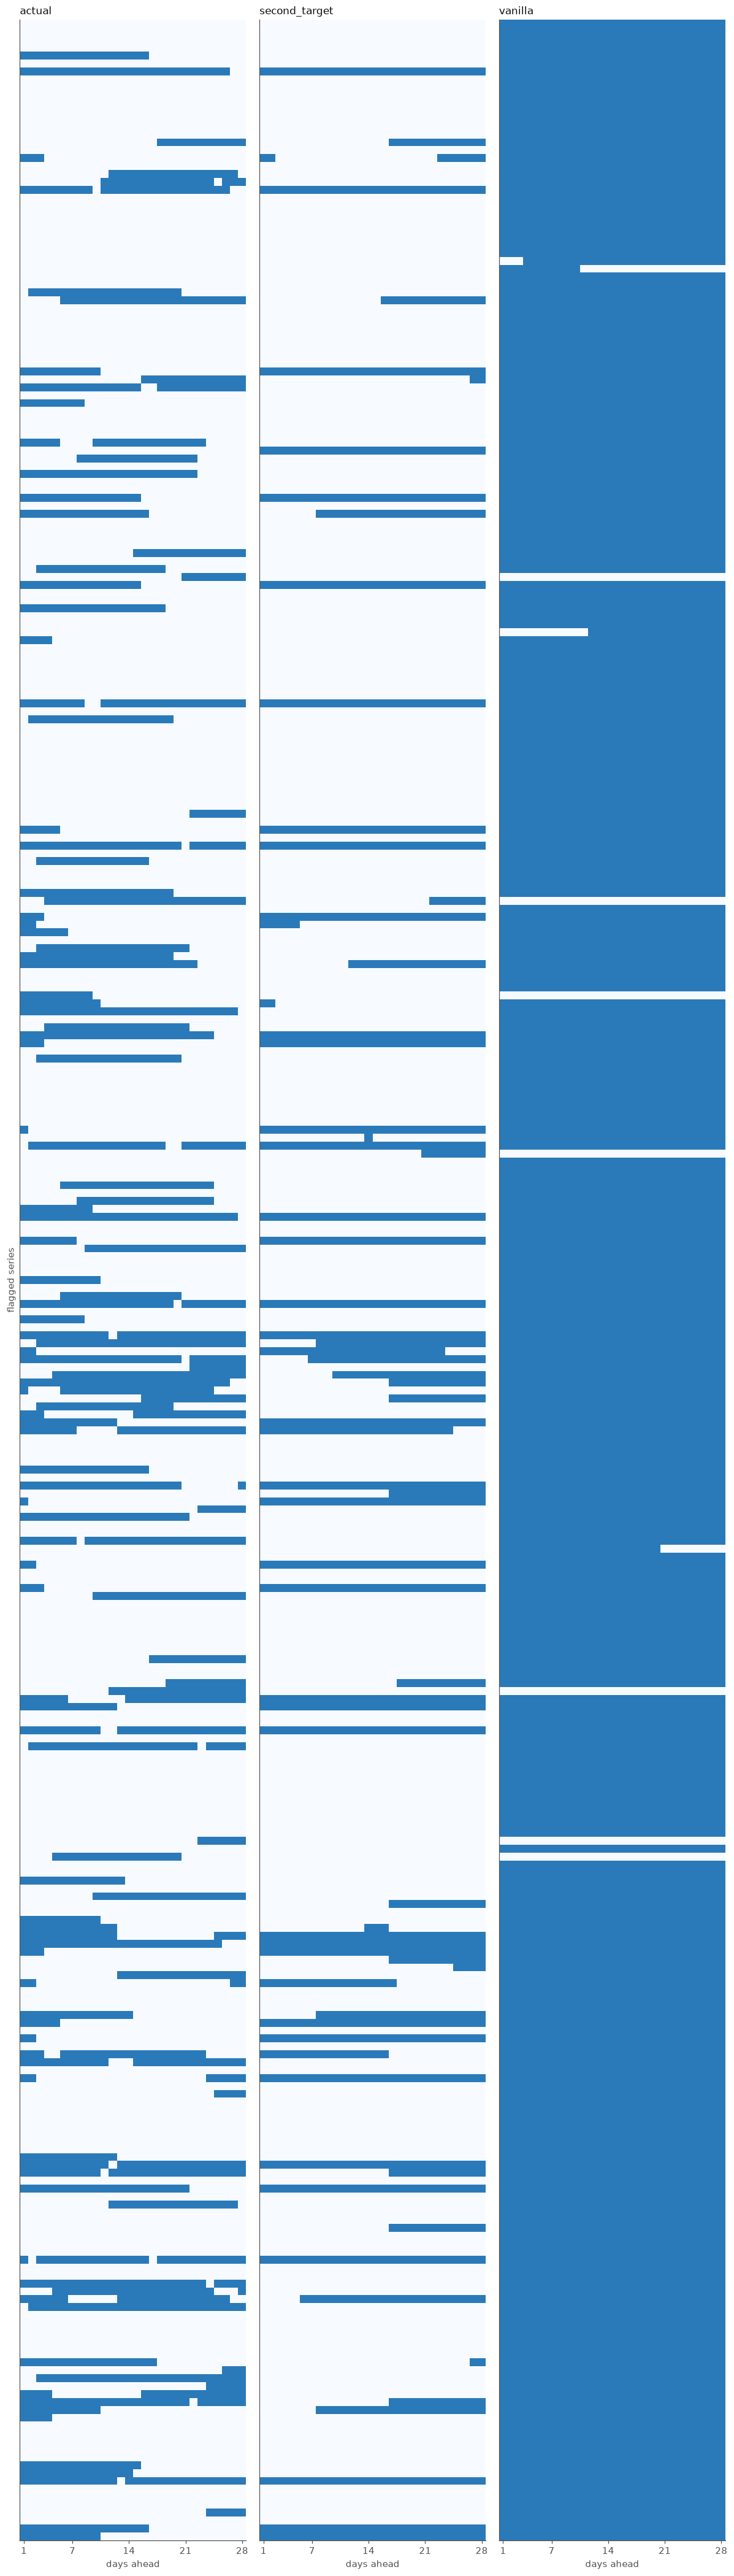

In [16]:
flagged_ids = (
    flags.group_by("id").agg(pl.col("actual", "second_target", "vanilla").any())
    .filter(pl.col("actual") | pl.col("second_target") | pl.col("vanilla"))["id"].sort().to_list()
)
print(f"{len(flagged_ids)} of {len(scored_ids)} scored series are flagged by at least one source")

if flagged_ids:
    sources = ["actual", "second_target", "vanilla"]
    fig, axes = plt.subplots(1, 3, figsize=(11, max(2.5, 0.12 * len(flagged_ids))), sharey=True)
    for ax, source in zip(axes, sources):
        grid = (
            flags.filter(pl.col("id").is_in(flagged_ids)).sort("id", "date")
            .pivot(on="date", index="id", values=source).sort("id").drop("id").to_numpy().astype(float)
        )
        ax.imshow(grid, aspect="auto", interpolation="nearest", cmap="Blues", vmin=0, vmax=1.4)
        ax.grid(False)
        ax.set_title(source, loc="left")
        ax.set_xlabel("days ahead")
        ax.set_xticks([0, 6, 13, 20, 27])
        ax.set_xticklabels([1, 7, 14, 21, 28])
    axes[0].set_ylabel("flagged series")
    axes[0].set_yticks([])
    fig.tight_layout()
    plt.show()

### 3c. Are the two channels coupled?

A second target only helps if a forecast blank period pulls the sales forecast down. Among the days where
the model is confident of a blank period (median of `is_blank` at least 0.5): how often is its sales
forecast *above* the vanilla one?

In [17]:
coupling = (
    multivariate.filter(pl.col("target_name") == "sales").select("id", "date", pl.col("y_pred").alias("sales_second_target"))
    .join(second_target_flags.filter(pl.col("second_target")), on=["id", "date"])
    .join(vanilla.select("id", "date", pl.col("y_pred").alias("sales_vanilla")), on=["id", "date"])
    .with_columns((pl.col("sales_second_target") - pl.col("sales_vanilla")).alias("excess"))
)
if coupling.height == 0:
    print("The model never forecasts a blank period with a median of 0.5 or more.")
else:
    print(f"Days with a confident blank-period forecast: {coupling.height}")
    print(f"  ... with a sales forecast above vanilla: {(coupling['excess'] > 0).mean():.0%}")
    print(f"  ... with a sales forecast below vanilla: {(coupling['excess'] < 0).mean():.0%}")

Days with a confident blank-period forecast: 2106
  ... with a sales forecast above vanilla: 38%
  ... with a sales forecast below vanilla: 61%


The clearest contradiction: the series and day where the model is sure of a blank period and forecasts the most sales above vanilla.

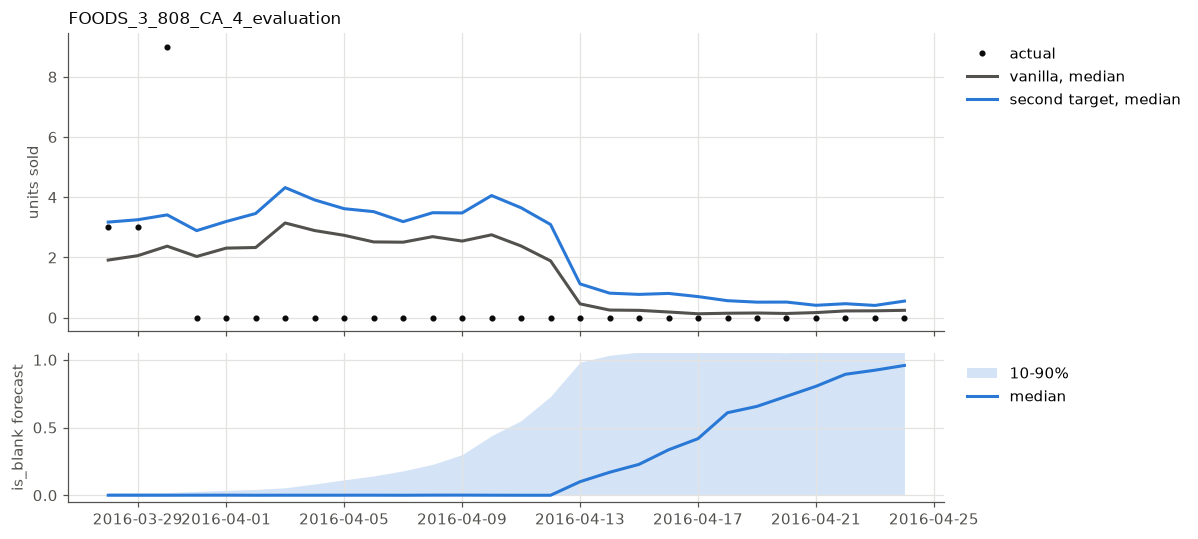

In [18]:
if coupling.height > 0 and coupling["excess"].max() > 0:
    worst_id = coupling.sort("excess", descending=True)["id"][0]
    days = lambda table: table.filter(pl.col("id") == worst_id).sort("date")
    actual = days(truth.filter(window))
    multi_sales = days(multivariate.filter(pl.col("target_name") == "sales"))
    multi_flag = days(multivariate.filter(pl.col("target_name") == "is_blank"))

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, height_ratios=[2, 1])
    top.plot(actual["date"].to_numpy(), actual["y"].to_numpy(), color=TEXT_COLOR, linestyle="none", marker="o", markersize=3, label="actual")
    top.plot(days(vanilla)["date"].to_numpy(), days(vanilla)["y_pred"].to_numpy(), color=MUTED_TEXT_COLOR, label="vanilla, median")
    top.plot(multi_sales["date"].to_numpy(), multi_sales["y_pred"].to_numpy(), color=MAIN_COLOR, label="second target, median")
    top.set_ylabel("units sold")
    top.set_title(worst_id, loc="left")
    top.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    bottom.fill_between(multi_flag["date"].to_numpy(), multi_flag["q0.1"].to_numpy(), multi_flag["q0.9"].to_numpy(),
                        color=MAIN_COLOR, alpha=0.2, linewidth=0, label="10-90%")
    bottom.plot(multi_flag["date"].to_numpy(), multi_flag["y_pred"].to_numpy(), color=MAIN_COLOR, label="median")
    bottom.set_ylim(-0.05, 1.05)
    bottom.set_ylabel("is_blank forecast")
    bottom.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    plt.show()

### 3d. The past-only covariate and the width of the distribution

Same pooled view as in section 1, for the blank-period covariate.

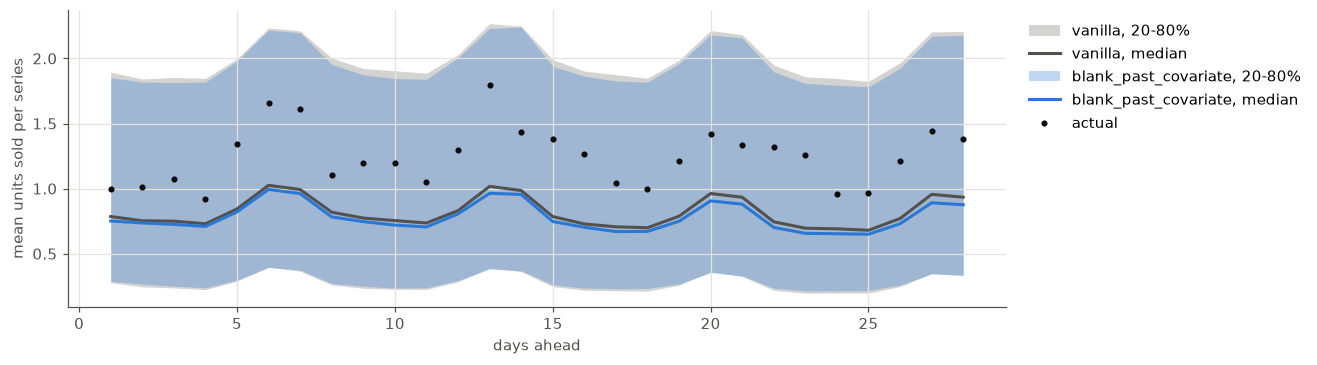

model,WQL_change_%,WMAPE_change_%,width_change_%
str,f64,f64,f32
"""vanilla""",0.0,0.0,0.0
"""blank_past_covariate""",0.099001,-0.079072,-2.672994


In [19]:
fig, ax = plt.subplots(figsize=(11, 3.5))
plot_bands(ax, "vanilla", "blank_past_covariate")
plt.show()

summary(["vanilla", "blank_past_covariate"]).select("model", "WQL_change_%", "WMAPE_change_%", "width_change_%")

Is the extra width only spent where blank periods happen? Width change against vanilla, split by whether
the series has an actual blank day in the window.

In [20]:
has_blank = flags.group_by("id").agg(pl.col("actual").any().alias("blank_in_window"))
width_split = (
    join_truth(runs["blank_past_covariate"], truth, validation_roster)
    .join(join_truth(vanilla, truth, validation_roster).select("id", "date", pl.col("q0.2").alias("v02"), pl.col("q0.8").alias("v08")), on=["id", "date"])
    .join(has_blank, on="id")
    .group_by("blank_in_window")
    .agg(
        pl.col("id").n_unique().alias("n_series"),
        (100 * ((pl.col("q0.8") - pl.col("q0.2")).mean() / (pl.col("v08") - pl.col("v02")).mean() - 1)).alias("width_change_%"),
    )
)
width_split

blank_in_window,n_series,width_change_%
bool,u32,f32
false,345,-3.074425
true,128,2.986717


## 4. Everything, against vanilla

Validation window. Left of zero: lower error than vanilla.

In [21]:
all_runs = ["vanilla"] + [name for name in known_runs + ["cross_learning"] + blank_runs if name != "vanilla"]
overall = summary(all_runs)
overall

model,n_series,MAE_change_%,WMAPE_change_%,P90_change_%,WQL_change_%,RQL_change_%,width_change_%
str,u32,f64,f64,f64,f64,f64,f32
"""vanilla""",473,-1.1102e-14,0.0,0.0,0.0,0.0,0.0
"""known_calendar""",473,0.364511,0.364511,1.374763,0.220327,1.873329,-0.341827
"""known_price""",473,0.455133,0.455133,0.85648,0.201992,-0.440306,-1.131165
"""known_snap_events""",473,0.156518,0.156518,1.070827,0.451685,0.940326,-2.418894
"""known_all_known""",473,-0.551397,-0.551397,-0.748552,-0.268642,-0.649223,-1.512814
"""cross_learning""",473,0.851014,0.851014,0.987333,1.122939,-5.605762,-3.662497
"""blank_past_covariate""",473,-0.079072,-0.079072,0.35964,0.099001,-3.593124,-2.672994
"""blank_second_target""",473,-0.079072,-0.079072,0.35964,0.099001,-3.593124,-2.672994
"""blank_nan_mask""",473,2.323921,2.323921,0.053463,1.98509,9.728935,11.261535


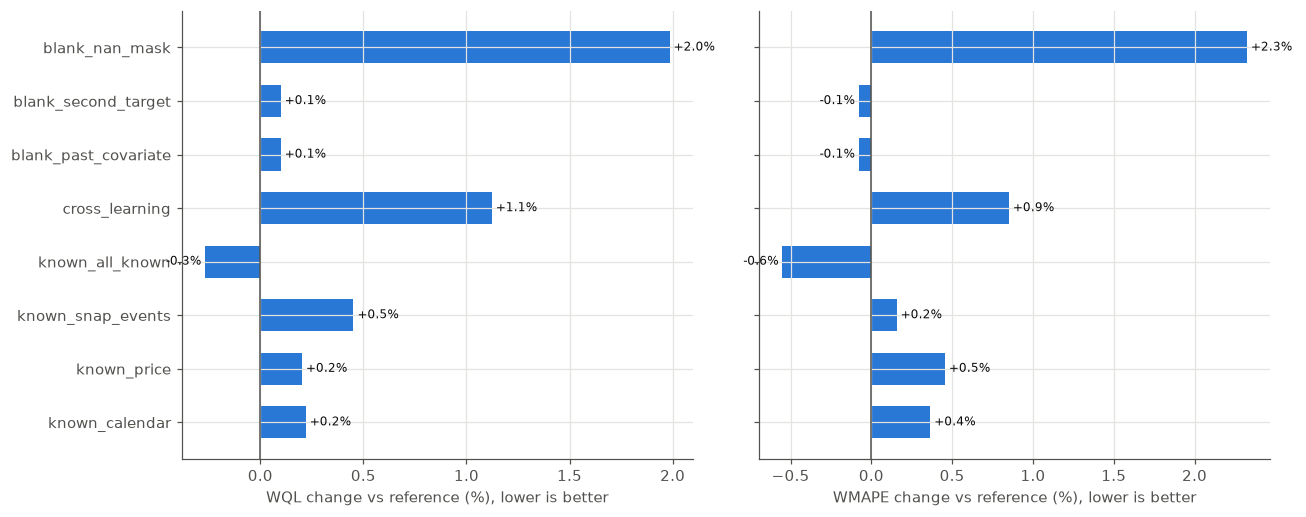

In [22]:
attempts = overall.filter(pl.col("model") != "vanilla")
fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * attempts.height + 1.2), sharey=True)
plot_change_bars(axes[0], attempts, "WQL")
plot_change_bars(axes[1], attempts, "WMAPE")
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()

## Notes

*Your observations here.*